In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import numpy as np
from matplotlib.lines import Line2D

# Đường dẫn tới file CSV
CSV_PATH = "../../outputs_evaluation/aggregated_k_shot_detailed.csv"

_df = pd.read_csv(CSV_PATH)
_df['Shots_Int'] = _df['Shots'].str.extract(r'(\d+)').astype(int)
_df['Pair'] = _df['Source'] + " ➔ " + _df['Target']

def plot_comparison(config_list, protocol, title_suffix="", show_plots=True, strict_mode=False):
    """
    - strict_mode=False: Vẽ TẤT CẢ các cặp (kể cả cặp thiếu 1 trong 2 config).
    - strict_mode=True: Chỉ vẽ những cặp có ĐỦ tất cả config.
    """
    configs = [tuple(item.split("/")) for item in config_list]
    config_names = [f"{m} ({b})" for m, b in configs]

    df_filtered = _df[_df['Protocol'] == protocol].copy()
    df_filtered['Config'] = df_filtered['Method'] + " (" + df_filtered['Backbone'] + ")"
    df_filtered = df_filtered[df_filtered['Config'].isin(config_names)]

    if df_filtered.empty:
        print(f"⚠️ Không có dữ liệu cho các cấu hình: {config_list} trong {protocol}")
        return

    # Lọc các cặp
    valid_pairs = []
    for pair in df_filtered['Pair'].unique():
        pair_data = df_filtered[df_filtered['Pair'] == pair]
        if strict_mode:
            if len(pair_data['Config'].unique()) == len(config_names) and pair_data['Shots_Int'].nunique() >= 3:
                valid_pairs.append(pair)
        else:
            if pair_data['Shots_Int'].nunique() >= 3:
                valid_pairs.append(pair)

    if not valid_pairs:
        print(f"⚠️ Không có cặp nào hợp lệ trong {protocol}")
        return

    # Xác định các Target làm Cột (4 tập dữ liệu đích -> 4 cột)
    targets = sorted(list(set([p.split(" ➔ ")[1] for p in valid_pairs])))
    n_cols = len(targets)

    # Tính số hàng tối đa (Mỗi cột chứa các Source hướng về Target đó)
    target_counts = {tgt: 0 for tgt in targets}
    for p in valid_pairs:
        target_counts[p.split(" ➔ ")[1]] += 1
    n_rows = max(target_counts.values())

    # Tăng kích thước chiều cao và chừa không gian phía trên cho Title & Legend
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4.2 * n_rows + 2.5), sharey=True)
    axes = np.atleast_2d(axes)
    if axes.shape[1] != n_cols:
        axes = axes.T

    palette = sns.color_palette("tab10", len(config_names))
    row_counters = {tgt: 0 for tgt in targets}

    # Sắp xếp các cặp theo Cột (Target) -> Hàng (Source)
    valid_pairs.sort(key=lambda x: (x.split(" ➔ ")[1], x.split(" ➔ ")[0]))

    # Vẽ từng subplot
    for pair in valid_pairs:
        src, tgt = pair.split(" ➔ ")
        col_idx = targets.index(tgt)
        row_idx = row_counters[tgt]

        ax = axes[row_idx, col_idx]
        df_pair = df_filtered[df_filtered['Pair'] == pair]

        sns.lineplot(
            data=df_pair, x='Shots_Int', y='F1_Mean', hue='Config',
            marker='o', linewidth=2, markersize=6, ax=ax, legend=False,
            palette=dict(zip(config_names, palette)), hue_order=config_names
        )

        ax.set_title(f'{pair}', fontsize=11, fontweight='bold', pad=10)
        ax.set_xlabel('Số lượng K-Shot', fontsize=9)

        if col_idx == 0:
            ax.set_ylabel('Macro F1-Score (%)', fontsize=9)
        else:
            ax.set_ylabel('')

        ax.set_xticks(sorted(df_pair['Shots_Int'].unique()))
        ax.set_ylim(10, 100)
        ax.grid(True, linestyle='--', alpha=0.6)

        row_counters[tgt] += 1

    # Ẩn các ô trống nếu có cột có ít hàng hơn
    for col_idx, tgt in enumerate(targets):
        for row_idx in range(row_counters[tgt], n_rows):
            axes[row_idx, col_idx].axis('off')

    # Đặt Tiêu đề chính cao hẳn lên trên
    fig.suptitle(f'So sánh F1-Score ({protocol} - {title_suffix})', fontsize=18, fontweight='bold', y=0.97)

    # Đặt Legend nằm ngay dưới Tiêu đề
    custom_lines = [Line2D([0], [0], color=palette[idx], lw=2, marker='o') for idx in range(len(config_names))]
    fig.legend(custom_lines, config_names, title='Cấu hình',
               loc='upper center', bbox_to_anchor=(0.5, 0.92),
               ncol=len(config_names), fontsize=11, title_fontsize=12,
               frameon=True, borderpad=0.6, columnspacing=2.0)

    # ĐẤY ĐỒ THỊ XUỐNG DƯỚI: top=0.75 chừa 25% phía trên hoàn toàn cho Title và Legend
    plt.subplots_adjust(top=0.75, bottom=0.08, left=0.06, right=0.98, wspace=0.18, hspace=0.45)

    if show_plots:
        plt.show()
    else:
        plt.close(fig)

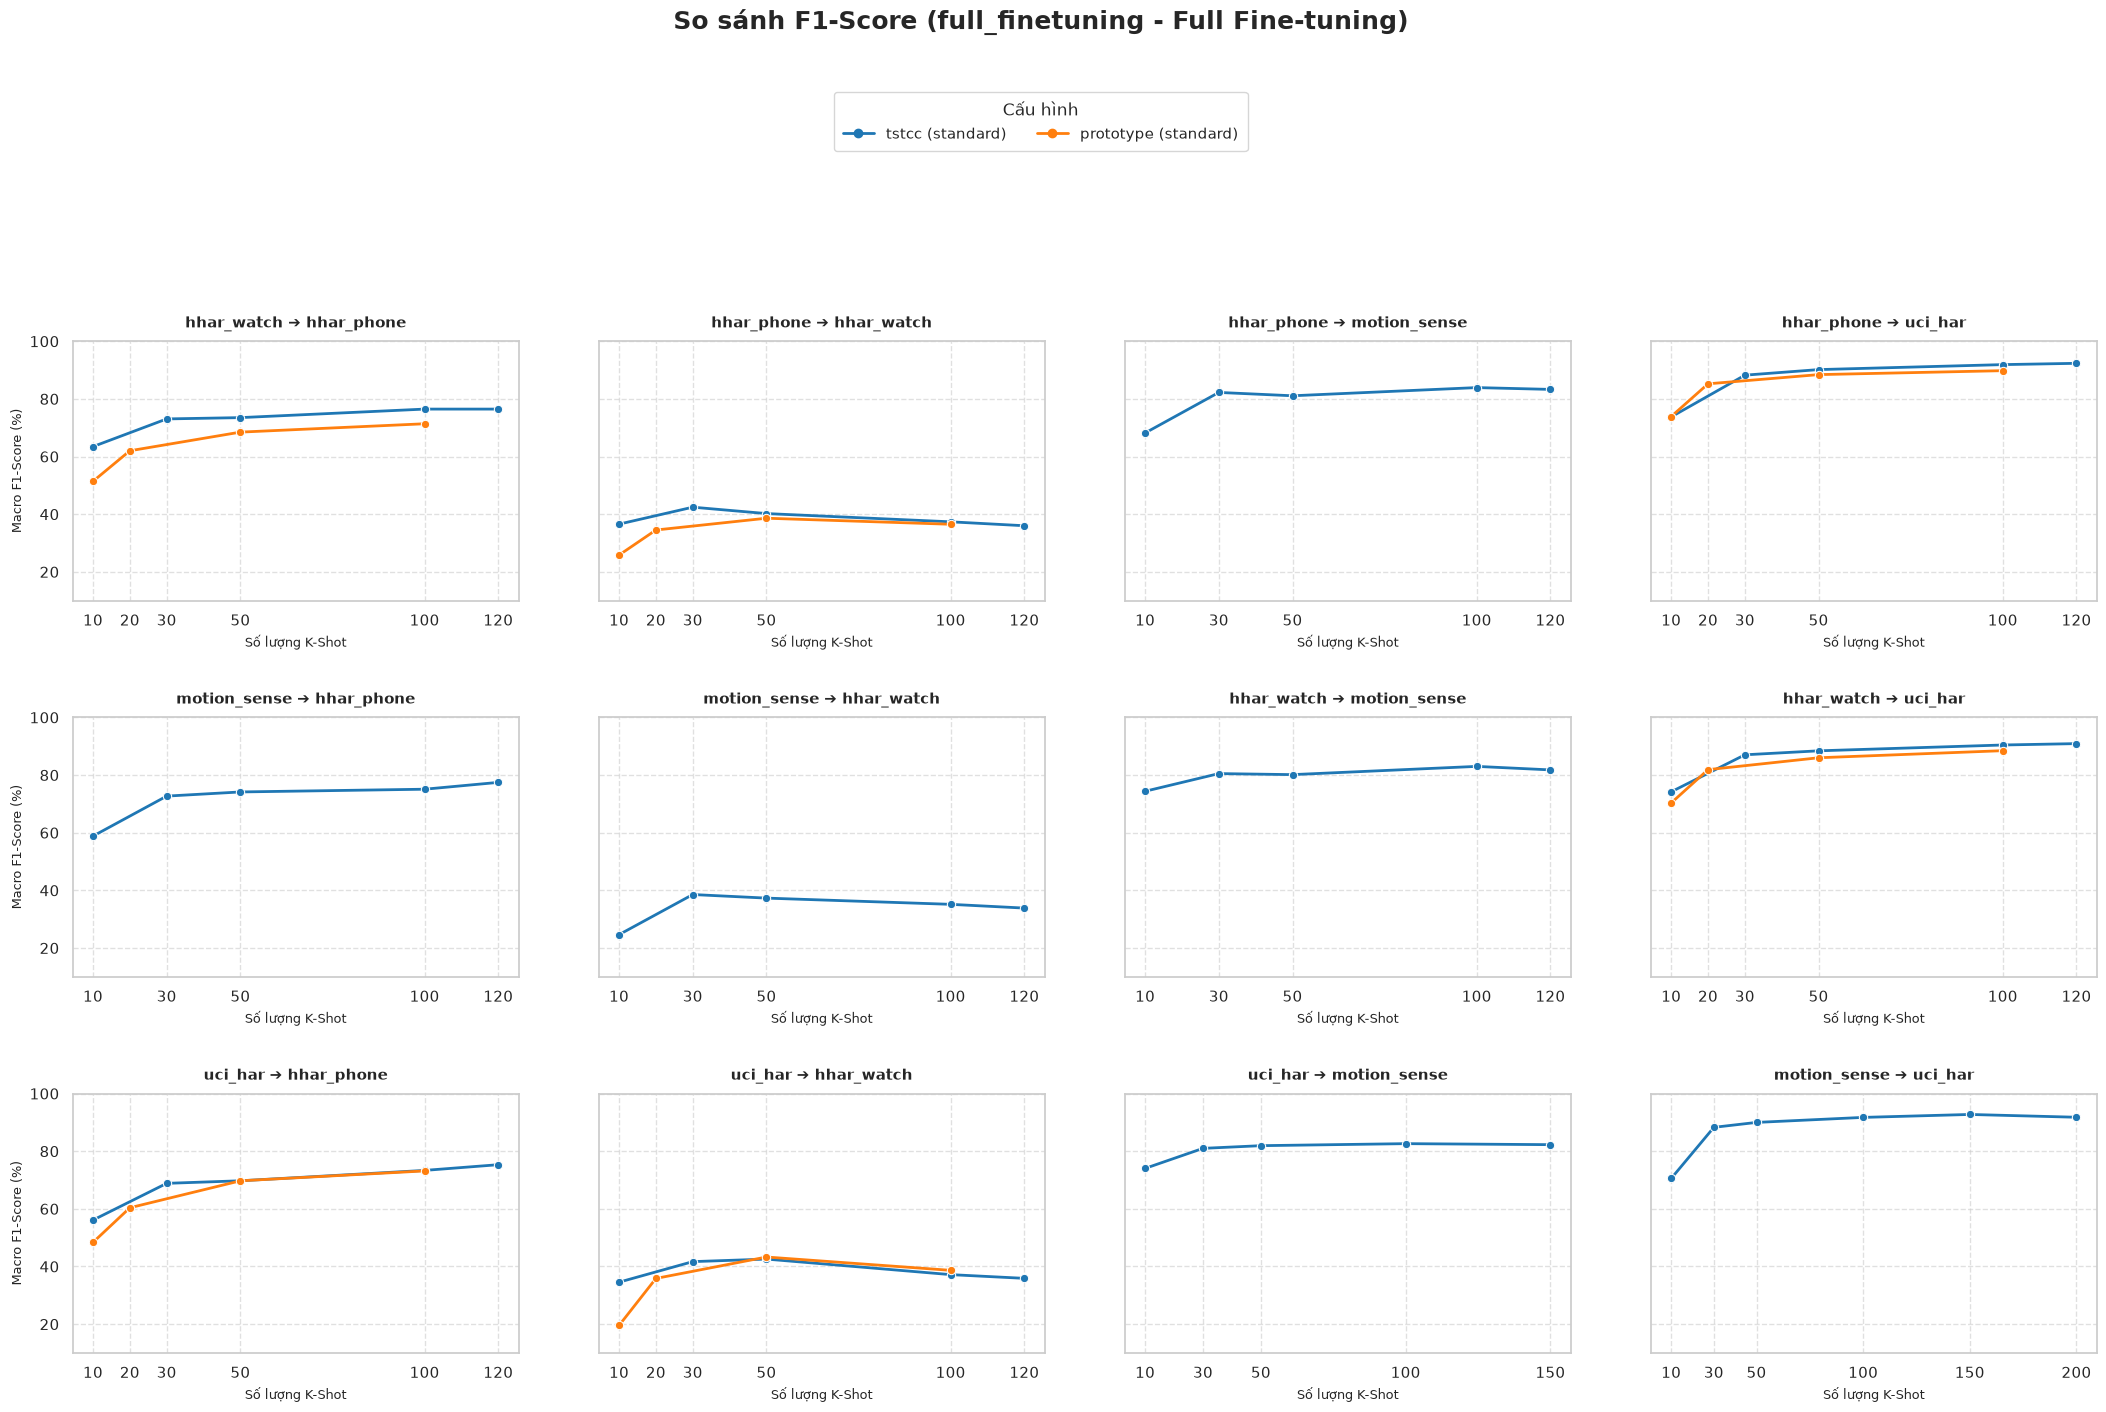

In [27]:
plot_comparison(
    config_list=["tstcc/standard", "prototype/standard"],
    protocol="full_finetuning",
    title_suffix="Full Fine-tuning"
)

In [25]:
import pandas as pd

CSV_PATH = "../../outputs_evaluation/aggregated_k_shot_detailed.csv"
df = pd.read_csv(CSV_PATH)

protocol = "full_finetuning"
config_list = ["tstcc/standard", "prototype/standard"]

# Lọc dữ liệu
df_proto = df[df['Protocol'] == protocol].copy()
df_proto['Config'] = df_proto['Method'] + " (" + df_proto['Backbone'] + ")"
config_names = [item.replace("/", " (") + ")" for item in config_list]

df_filtered = df_proto[df_proto['Config'].isin(config_names)].copy()
df_filtered['Pair'] = df_filtered['Source'] + " ➔ " + df_filtered['Target']

print("=== 1. TẤT CẢ CÁC CẶP CÓ TRONG FILE CSV ===")
all_pairs = df_filtered['Pair'].unique()
print(f"Tổng số cặp tìm thấy: {len(all_pairs)}")
for p in all_pairs:
    print(" -", p)

print("\n=== 2. KIỂM TRA SỐ CẤU HÌNH CÓ TRONG MỖI CẶP ===")
for p in all_pairs:
    p_data = df_filtered[df_filtered['Pair'] == p]
    configs_present = p_data['Config'].unique()
    shots_count = p_data['Shots'].nunique()
    print(f"Cặp: {p:<30} | Số Config: {len(configs_present)}/{len(config_names)} | Số K-Shot: {shots_count}")

=== 1. TẤT CẢ CÁC CẶP CÓ TRONG FILE CSV ===
Tổng số cặp tìm thấy: 12
 - hhar_phone ➔ motion_sense
 - motion_sense ➔ hhar_phone
 - hhar_watch ➔ uci_har
 - motion_sense ➔ hhar_watch
 - hhar_watch ➔ hhar_phone
 - hhar_watch ➔ motion_sense
 - uci_har ➔ motion_sense
 - hhar_phone ➔ uci_har
 - uci_har ➔ hhar_phone
 - hhar_phone ➔ hhar_watch
 - uci_har ➔ hhar_watch
 - motion_sense ➔ uci_har

=== 2. KIỂM TRA SỐ CẤU HÌNH CÓ TRONG MỖI CẶP ===
Cặp: hhar_phone ➔ motion_sense      | Số Config: 1/2 | Số K-Shot: 5
Cặp: motion_sense ➔ hhar_phone      | Số Config: 1/2 | Số K-Shot: 5
Cặp: hhar_watch ➔ uci_har           | Số Config: 2/2 | Số K-Shot: 6
Cặp: motion_sense ➔ hhar_watch      | Số Config: 1/2 | Số K-Shot: 5
Cặp: hhar_watch ➔ hhar_phone        | Số Config: 2/2 | Số K-Shot: 6
Cặp: hhar_watch ➔ motion_sense      | Số Config: 1/2 | Số K-Shot: 5
Cặp: uci_har ➔ motion_sense         | Số Config: 1/2 | Số K-Shot: 5
Cặp: hhar_phone ➔ uci_har           | Số Config: 2/2 | Số K-Shot: 6
Cặp: uci_har ➔ hhar